**Vehicle Price Prediction Machine Learning Project**

**Overview:** This regression machine learning project utilizes a used car dataset to predict the continuous variable of vehicle selling price. Notebook sections include exploratory data analysis, visualization EDA, and machine learning. Ridge and Gradient Boosting regression models are employed with the final model being chosen based on cross validation scoring. Regression metrics including R2, MSE, and MAE are calculated to determine final model performance. Finally, feature evaluation is completed to determine which data set features possessed the highest predictive power of the continuous target variable.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, TargetEncoder, OneHotEncoder

In [2]:
#Set notebook and plotting options
plt.style.use('ggplot')
%matplotlib inline
output_divider = '=' * 130
pd.options.display.float_format = '{:,.2f}'.format
fontsize = 12
fontweight = 'bold'

**Part 1: Initial EDA & Data Cleaning**

In [3]:
print("Load Data:")
print(output_divider)
df = pd.read_csv(r"C:\Users\natha\OneDrive\Documents\ISM 645\car_prices.csv")
print("First Ten Rows Of Data:")
df.head(10)

Load Data:
First Ten Rows Of Data:


,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.00,"16,639.00",white,black,kia motors america inc,"20,500.00","21,500.00",Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.00,"9,393.00",white,beige,kia motors america inc,"20,800.00","21,500.00",Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.00,"1,331.00",gray,black,financial services remarketing (lease),"31,900.00","30,000.00",Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.00,"14,282.00",white,black,volvo na rep/world omni,"27,500.00","27,750.00",Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.00,"2,641.00",gray,black,financial services remarketing (lease),"66,000.00","67,000.00",Thu Dec 18 2014 12:30:00 GMT-0800 (PST)
5,2015,Nissan,Altima,2.5 S,Sedan,automatic,1n4al3ap1fn326013,ca,1.00,"5,554.00",gray,black,enterprise vehicle exchange / tra / rental / t...,"15,350.00","10,900.00",Tue Dec 30 2014 12:00:00 GMT-0800 (PST)
6,2014,BMW,M5,Base,Sedan,automatic,wbsfv9c51ed593089,ca,34.00,"14,943.00",black,black,the hertz corporation,"69,000.00","65,000.00",Wed Dec 17 2014 12:30:00 GMT-0800 (PST)
7,2014,Chevrolet,Cruze,1LT,Sedan,automatic,1g1pc5sb2e7128460,ca,2.00,"28,617.00",black,black,enterprise vehicle exchange / tra / rental / t...,"11,900.00","9,800.00",Tue Dec 16 2014 13:00:00 GMT-0800 (PST)
8,2014,Audi,A4,2.0T Premium Plus quattro,Sedan,automatic,wauffafl3en030343,ca,42.00,"9,557.00",white,black,audi mission viejo,"32,100.00","32,250.00",Thu Dec 18 2014 12:00:00 GMT-0800 (PST)
9,2014,Chevrolet,Camaro,LT,Convertible,automatic,2g1fb3d37e9218789,ca,3.00,"4,809.00",red,black,d/m auto sales inc,"26,300.00","17,500.00",Tue Jan 20 2015 04:00:00 GMT-0800 (PST)


In [4]:
for cols in df.columns:
    print(cols)

year
make
model
trim
body
transmission
vin
state
condition
odometer
color
interior
seller
mmr
sellingprice
saledate


In [5]:
df.columns = df.columns.str.capitalize()
for upper_cols in df.columns:
    print(upper_cols)
print(output_divider)
print("Confirm Capitalization To Features:")
df.head()

Year
Make
Model
Trim
Body
Transmission
Vin
State
Condition
Odometer
Color
Interior
Seller
Mmr
Sellingprice
Saledate
Confirm Capitalization To Features:


,Year,Make,Model,Trim,Body,Transmission,Vin,State,Condition,Odometer,Color,Interior,Seller,Mmr,Sellingprice,Saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.00,"16,639.00",white,black,kia motors america inc,"20,500.00","21,500.00",Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.00,"9,393.00",white,beige,kia motors america inc,"20,800.00","21,500.00",Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.00,"1,331.00",gray,black,financial services remarketing (lease),"31,900.00","30,000.00",Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.00,"14,282.00",white,black,volvo na rep/world omni,"27,500.00","27,750.00",Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.00,"2,641.00",gray,black,financial services remarketing (lease),"66,000.00","67,000.00",Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


In [6]:
print("Data Frame Shape:", df.shape, '|', "Data Frame Size:", df.size)
print(output_divider)
print("Data Types & Initial Missing Data Inspection:")
print(output_divider)
df.info()

Data Frame Shape: (558837, 16) | Data Frame Size: 8941392
Data Types & Initial Missing Data Inspection:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 558837 entries, 0 to 558836
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Year          558837 non-null  int64  
 1   Make          548536 non-null  object 
 2   Model         548438 non-null  object 
 3   Trim          548186 non-null  object 
 4   Body          545642 non-null  object 
 5   Transmission  493485 non-null  object 
 6   Vin           558833 non-null  object 
 7   State         558837 non-null  object 
 8   Condition     547017 non-null  float64
 9   Odometer      558743 non-null  float64
 10  Color         558088 non-null  object 
 11  Interior      558088 non-null  object 
 12  Seller        558837 non-null  object 
 13  Mmr           558799 non-null  float64
 14  Sellingprice  558825 non-null  float64
 15  Saledate      558825 non-null  o

In [7]:
print("Summary Level Statistics On Numeric Columns:")
df.describe()

Summary Level Statistics On Numeric Columns:


,Year,Condition,Odometer,Mmr,Sellingprice
count,"558,837.00","547,017.00","558,743.00","558,799.00","558,825.00"
mean,"2,010.04",30.67,"68,320.02","13,769.38","13,611.36"
std,3.97,13.40,"53,398.54","9,679.97","9,749.50"
min,"1,982.00",1.00,1.00,25.00,1.00
25%,"2,007.00",23.00,"28,371.00","7,100.00","6,900.00"
50%,"2,012.00",35.00,"52,254.00","12,250.00","12,100.00"
75%,"2,013.00",42.00,"99,109.00","18,300.00","18,200.00"
max,"2,015.00",49.00,"999,999.00","182,000.00","230,000.00"


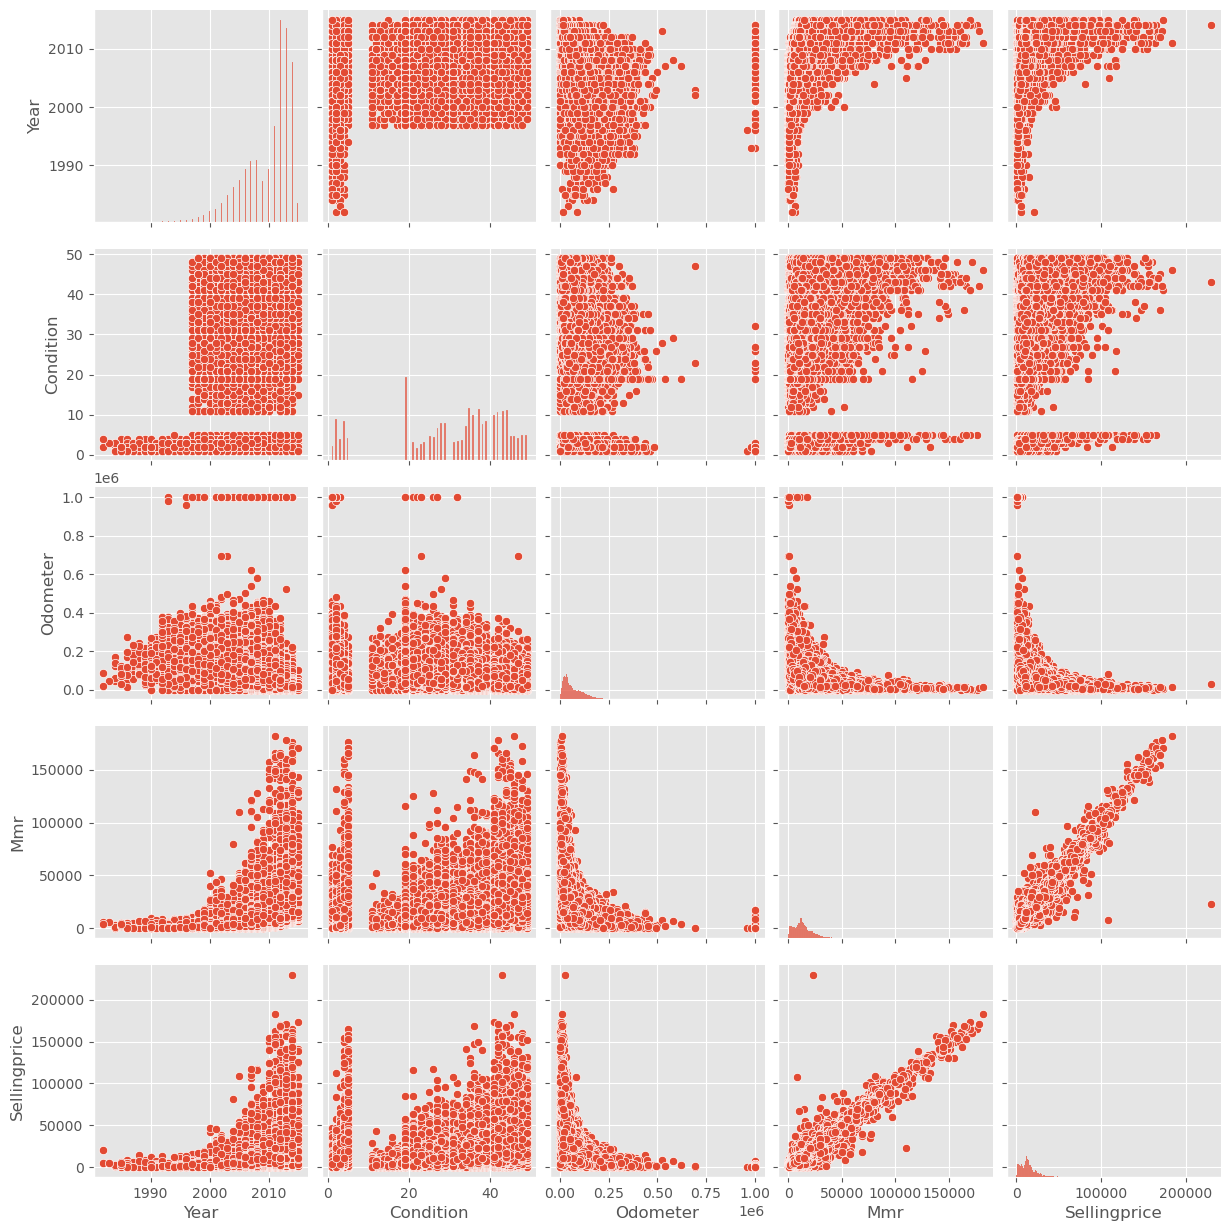

In [8]:
sns.pairplot(data=df, vars=[
    'Year',
    'Condition',
    'Odometer',
    'Mmr',
    'Sellingprice'])
plt.show()

In [9]:
print("Summary Level Statistics On Categorical Columns:")
df.describe(include='object')

Summary Level Statistics On Categorical Columns:


,Make,Model,Trim,Body,Transmission,Vin,State,Color,Interior,Seller,Saledate
count,548536,548438,548186,545642,493485,558833,558837,558088,558088,558837,558825
unique,96,973,1963,87,4,550297,64,46,17,14263,3766
top,Ford,Altima,Base,Sedan,automatic,automatic,fl,black,black,nissan-infiniti lt,Tue Feb 10 2015 01:30:00 GMT-0800 (PST)
freq,93554,19349,55817,199437,475915,22,82945,110970,244329,19693,5334


In [10]:
objects = df.select_dtypes(include=['object']).columns.tolist()
print("Categorical Features:", objects)

Categorical Features: ['Make', 'Model', 'Trim', 'Body', 'Transmission', 'Vin', 'State', 'Color', 'Interior', 'Seller', 'Saledate']


In [11]:
#Remove unneeded high cardinality features
df = df.drop(columns=['Trim', 'Vin', 'Seller', 'Saledate'], axis=1)
print("Remaining Features:", df.columns)

Remaining Features: Index(['Year', 'Make', 'Model', 'Body', 'Transmission', 'State', 'Condition',
       'Odometer', 'Color', 'Interior', 'Mmr', 'Sellingprice'],
      dtype='object')


In [12]:
print("Unique Makes:", df['Make'].unique().tolist())
print(output_divider)
print("Unique States:", df['State'].unique().tolist())
print(output_divider)
print("Unique Colors:", df['Color'].unique().tolist())
print(output_divider)
print("Unique Transmissions:", df['Transmission'].unique().tolist())
print(output_divider)
print("Unique Interiors:", df['Interior'].unique().tolist())

Unique Makes: ['Kia', 'BMW', 'Volvo', 'Nissan', 'Chevrolet', 'Audi', 'Ford', 'Hyundai', 'Buick', 'Cadillac', 'Acura', 'Lexus', 'Infiniti', 'Jeep', 'Mercedes-Benz', 'Mitsubishi', 'Mazda', 'MINI', 'Land Rover', 'Lincoln', 'lincoln', 'Jaguar', 'Volkswagen', 'Toyota', 'Subaru', 'Scion', 'Porsche', nan, 'bmw', 'Dodge', 'FIAT', 'Chrysler', 'ford', 'Ferrari', 'Honda', 'GMC', 'mitsubishi', 'Ram', 'smart', 'chevrolet', 'Bentley', 'chrysler', 'pontiac', 'Pontiac', 'Saturn', 'Maserati', 'Mercury', 'HUMMER', 'landrover', 'cadillac', 'land rover', 'mercedes', 'mazda', 'toyota', 'lexus', 'gmc truck', 'honda', 'nissan', 'porsche', 'Saab', 'Suzuki', 'dodge', 'subaru', 'Oldsmobile', 'oldsmobile', 'hyundai', 'jeep', 'Isuzu', 'dodge tk', 'Geo', 'acura', 'volkswagen', 'suzuki', 'kia', 'audi', 'Rolls-Royce', 'gmc', 'maserati', 'mazda tk', 'mercury', 'buick', 'hyundai tk', 'mercedes-b', 'vw', 'Daewoo', 'chev truck', 'ford tk', 'plymouth', 'Plymouth', 'ford truck', 'Tesla', 'airstream', 'dot', 'Aston Martin'

In [13]:
print("Standardize Capitalization For Categorical Features And Remove Junk Values:")
print(output_divider)
df['Make'] = df['Make'].str.capitalize()
df['State'] = df['State'].str.upper()
df = df[df['State'].str.len() <= 2]
df['Color'] = df['Color'].str.capitalize()
df['Transmission'] = df['Transmission'].str.capitalize()
df['Interior'] = df['Interior'].str.capitalize()
print("Unique Makes:", df['Make'].unique().tolist())
print(output_divider)
print("Unique States:", df['State'].unique().tolist())
print(output_divider)
print("Unique Colors:", df['Color'].unique().tolist())
print(output_divider)
print("Unique Transmissions:", df['Transmission'].unique().tolist())
print(output_divider)
print("Unique Interiors:", df['Interior'].unique().tolist())

Standardize Capitalization For Categorical Features And Remove Junk Values:
Unique Makes: ['Kia', 'Bmw', 'Volvo', 'Nissan', 'Chevrolet', 'Audi', 'Ford', 'Hyundai', 'Buick', 'Cadillac', 'Acura', 'Lexus', 'Infiniti', 'Jeep', 'Mercedes-benz', 'Mitsubishi', 'Mazda', 'Mini', 'Land rover', 'Lincoln', 'Jaguar', 'Volkswagen', 'Toyota', 'Subaru', 'Scion', 'Porsche', nan, 'Dodge', 'Fiat', 'Chrysler', 'Ferrari', 'Honda', 'Gmc', 'Ram', 'Smart', 'Bentley', 'Pontiac', 'Saturn', 'Maserati', 'Mercury', 'Hummer', 'Landrover', 'Mercedes', 'Gmc truck', 'Saab', 'Suzuki', 'Oldsmobile', 'Isuzu', 'Dodge tk', 'Geo', 'Rolls-royce', 'Mazda tk', 'Hyundai tk', 'Mercedes-b', 'Vw', 'Daewoo', 'Chev truck', 'Ford tk', 'Plymouth', 'Ford truck', 'Tesla', 'Airstream', 'Dot', 'Aston martin', 'Fisker', 'Lamborghini', 'Lotus']
Unique States: ['CA', 'TX', 'PA', 'MN', 'AZ', 'WI', 'TN', 'MD', 'FL', 'NE', 'NJ', 'NV', 'OH', 'MI', 'GA', 'VA', 'SC', 'NC', 'IN', 'IL', 'CO', 'UT', 'MO', 'NY', 'MA', 'PR', 'OR', 'LA', 'WA', 'HI', 'QC

In [14]:
missing_data = df.isna().sum().sort_values(ascending=True)
print("Missing Data By Feature:")
print(missing_data)
print(output_divider)
print("Data Types:")
print(df.dtypes)

Missing Data By Feature:
Year                0
State               0
Mmr                12
Sellingprice       12
Odometer           94
Interior          749
Color             749
Make            10301
Model           10399
Condition       11794
Body            13195
Transmission    65352
dtype: int64
Data Types:
Year              int64
Make             object
Model            object
Body             object
Transmission     object
State            object
Condition       float64
Odometer        float64
Color            object
Interior         object
Mmr             float64
Sellingprice    float64
dtype: object


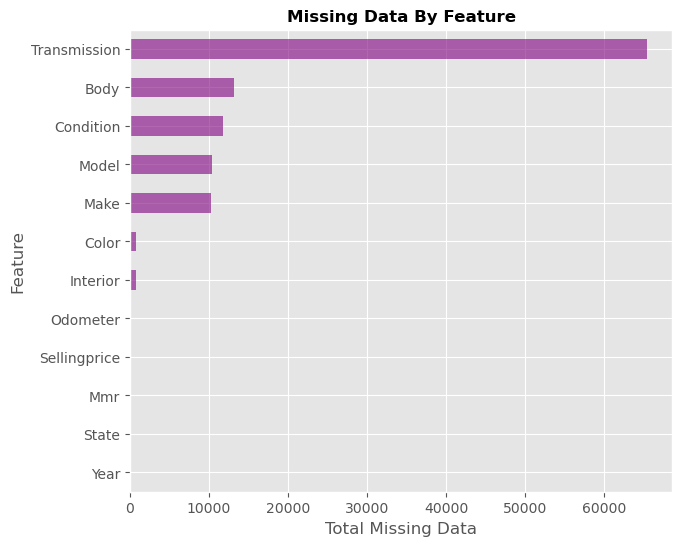

In [15]:
plt.figure(figsize=(7,6))
missing_data.plot(kind='barh', color='purple', alpha=0.6)
plt.title("Missing Data By Feature", fontsize=fontsize,
          fontweight=fontweight)
plt.xlabel("Total Missing Data")
plt.ylabel("Feature")
plt.show()

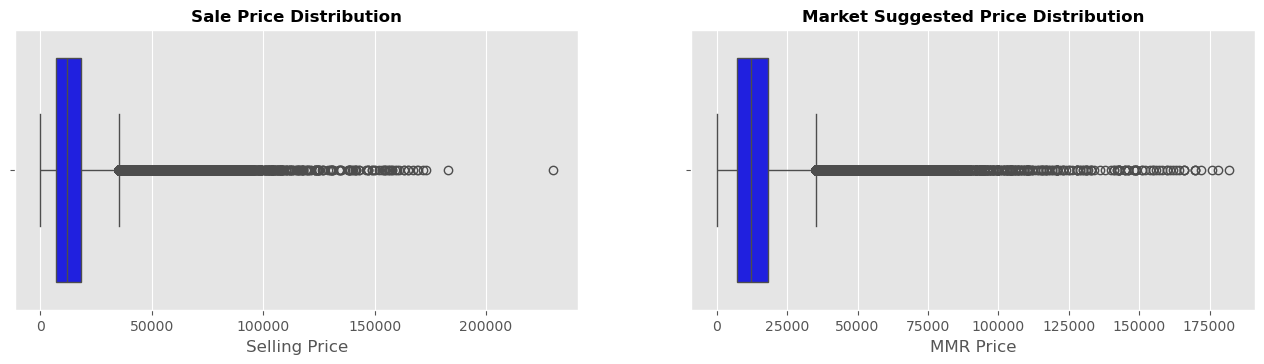

In [16]:
plt.figure(figsize=(16,8))
plt.subplot(2,2,1)
sns.boxplot(data=df, x='Sellingprice', color='blue')
plt.title("Sale Price Distribution",
         fontsize=fontsize, fontweight=fontweight)
plt.xlabel("Selling Price")
plt.subplot(2,2,2)
sns.boxplot(data=df, x='Mmr', color='blue')
plt.title("Market Suggested Price Distribution", fontsize=fontsize, fontweight=fontweight)
plt.xlabel("MMR Price")
plt.show()

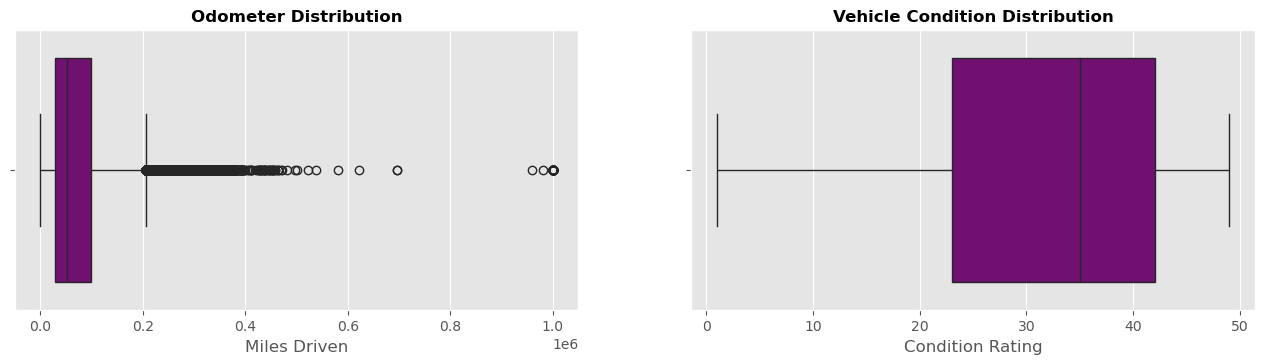

In [17]:
plt.figure(figsize=(16,8))
plt.subplot(2,2,1)
sns.boxplot(data=df, x='Odometer', color='purple')
plt.title("Odometer Distribution",
         fontsize=fontsize, fontweight=fontweight)
plt.xlabel("Miles Driven")
plt.subplot(2,2,2)
sns.boxplot(data=df, x='Condition', color='purple')
plt.title("Vehicle Condition Distribution", fontsize=fontsize, fontweight=fontweight)
plt.xlabel("Condition Rating")
plt.show()

In [18]:
#Fill missing numeric data with median and drop missing categorical data
df = df.fillna(df.median(numeric_only=True))
print("Remaing Missing Data:")
print(df.isna().sum().sort_values(ascending=True))

Remaing Missing Data:
Year                0
Odometer            0
Condition           0
State               0
Mmr                 0
Sellingprice        0
Color             749
Interior          749
Make            10301
Model           10399
Body            13195
Transmission    65352
dtype: int64


In [19]:
df.dropna(subset=['Color', 'Interior', 'Make', 'Model', 'Body', 'Transmission'], inplace=True)
print("Confirm No More Missing Data:")
print(df.isna().sum())
print(output_divider)
print("Cleaned Data Frame Shape:", df.shape)
print(output_divider)
print("Summary Level Statistics After Cleaning:")
df.describe()

Confirm No More Missing Data:
Year            0
Make            0
Model           0
Body            0
Transmission    0
State           0
Condition       0
Odometer        0
Color           0
Interior        0
Mmr             0
Sellingprice    0
dtype: int64
Cleaned Data Frame Shape: (481758, 12)
Summary Level Statistics After Cleaning:


,Year,Condition,Odometer,Mmr,Sellingprice
count,"481,758.00","481,758.00","481,758.00","481,758.00","481,758.00"
mean,"2,010.12",30.86,"67,695.10","13,702.35","13,550.27"
std,3.88,13.17,"52,508.41","9,535.78","9,613.58"
min,"1,990.00",1.00,1.00,25.00,1.00
25%,"2,008.00",24.00,"28,441.25","7,200.00","7,000.00"
50%,"2,012.00",35.00,"52,076.00","12,200.00","12,100.00"
75%,"2,013.00",41.00,"98,195.00","18,150.00","18,000.00"
max,"2,015.00",49.00,"999,999.00","182,000.00","230,000.00"


**Part 2: Visualization EDA**

In [20]:
print("Data Types:", df.dtypes)
print(output_divider)
print("Data Frame Header:")
df.head()

Data Types: Year              int64
Make             object
Model            object
Body             object
Transmission     object
State            object
Condition       float64
Odometer        float64
Color            object
Interior         object
Mmr             float64
Sellingprice    float64
dtype: object
Data Frame Header:


,Year,Make,Model,Body,Transmission,State,Condition,Odometer,Color,Interior,Mmr,Sellingprice
0,2015,Kia,Sorento,SUV,Automatic,CA,5.00,"16,639.00",White,Black,"20,500.00","21,500.00"
1,2015,Kia,Sorento,SUV,Automatic,CA,5.00,"9,393.00",White,Beige,"20,800.00","21,500.00"
2,2014,Bmw,3 Series,Sedan,Automatic,CA,45.00,"1,331.00",Gray,Black,"31,900.00","30,000.00"
3,2015,Volvo,S60,Sedan,Automatic,CA,41.00,"14,282.00",White,Black,"27,500.00","27,750.00"
4,2014,Bmw,6 Series Gran Coupe,Sedan,Automatic,CA,43.00,"2,641.00",Gray,Black,"66,000.00","67,000.00"


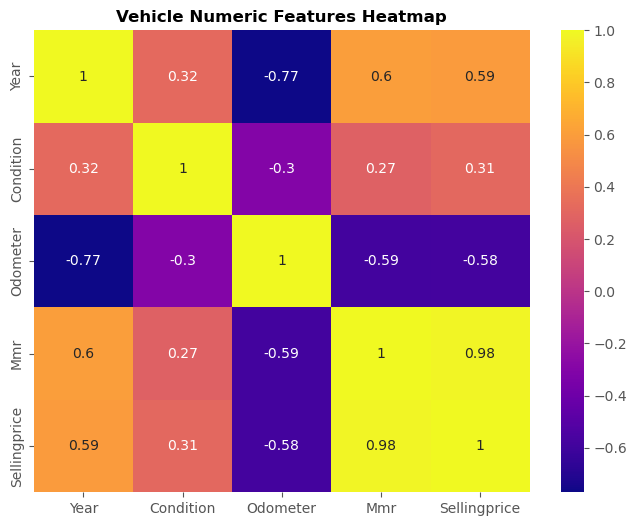

In [21]:
corr = df.select_dtypes(include=['int64', 'float64']).corr().round(2)
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='plasma')
plt.title("Vehicle Numeric Features Heatmap", fontweight=fontweight,
          fontsize=fontsize)
plt.show()

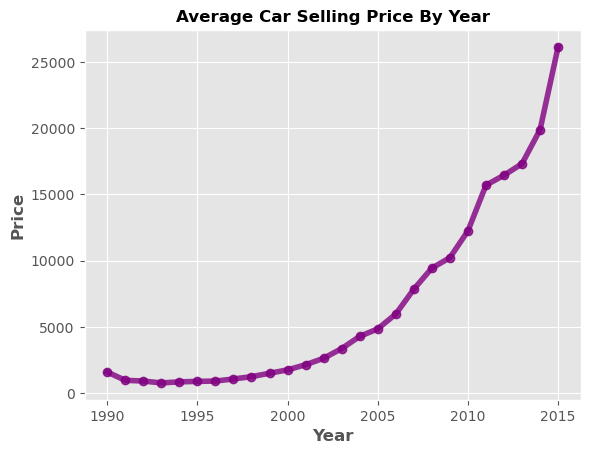

In [22]:
year_price = df.groupby('Year')['Sellingprice'].mean()
year_price.plot(kind='line', color='purple', marker='o', alpha=0.8, linewidth=4)
plt.title("Average Car Selling Price By Year", fontweight=fontweight,
          fontsize=fontsize)
plt.xlabel("Year", fontweight=fontweight)
plt.ylabel("Price", fontweight=fontweight)
plt.show()

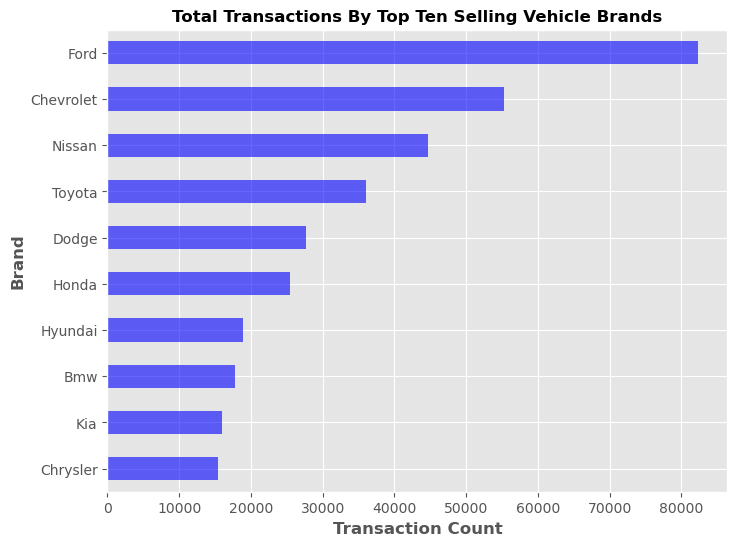

In [23]:
transactions_brand = df['Make'].value_counts().head(10).sort_values(ascending=True)
plt.figure(figsize=(8,6))
transactions_brand.plot(kind='barh', color='blue', alpha=0.6)
plt.title("Total Transactions By Top Ten Selling Vehicle Brands", fontweight=fontweight,
          fontsize=fontsize)
plt.xlabel("Transaction Count", fontweight=fontweight)
plt.ylabel("Brand", fontweight=fontweight)
plt.show()

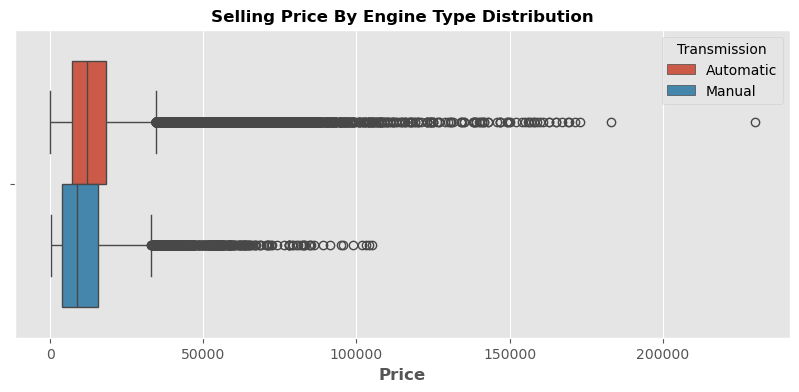

In [24]:
plt.figure(figsize=(10,4))
sns.boxplot(data=df, x='Sellingprice', hue='Transmission')
plt.title("Selling Price By Engine Type Distribution", fontsize=fontsize,
          fontweight=fontweight)
plt.xlabel("Price", fontweight=fontweight)
plt.show()

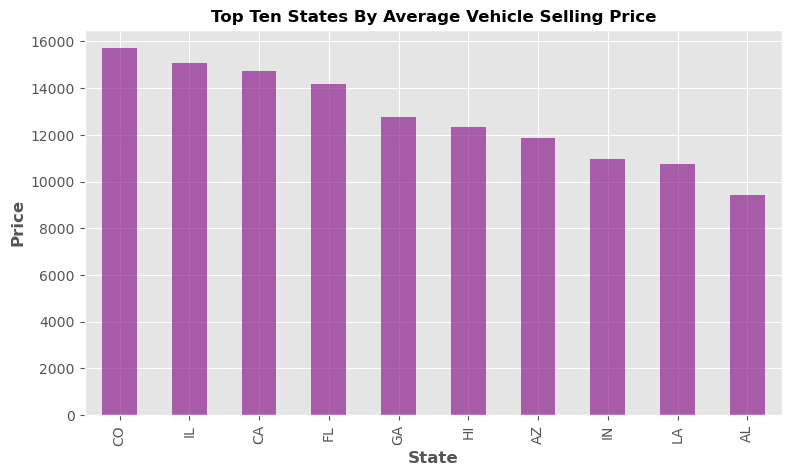

In [25]:
state_price = df.groupby('State')['Sellingprice'].mean().head(10).sort_values(ascending=False)
plt.figure(figsize=(9,5))
state_price.plot(kind='bar', color='purple', alpha=0.6)
plt.title("Top Ten States By Average Vehicle Selling Price", fontweight=fontweight, 
          fontsize=fontsize)
plt.xlabel("State", fontweight=fontweight)
plt.ylabel("Price", fontweight=fontweight)
plt.show()

**Part 3: Machine Learning**

In [26]:
print("Data Types", df.dtypes)
print(output_divider)
df.head()

Data Types Year              int64
Make             object
Model            object
Body             object
Transmission     object
State            object
Condition       float64
Odometer        float64
Color            object
Interior         object
Mmr             float64
Sellingprice    float64
dtype: object


,Year,Make,Model,Body,Transmission,State,Condition,Odometer,Color,Interior,Mmr,Sellingprice
0,2015,Kia,Sorento,SUV,Automatic,CA,5.00,"16,639.00",White,Black,"20,500.00","21,500.00"
1,2015,Kia,Sorento,SUV,Automatic,CA,5.00,"9,393.00",White,Beige,"20,800.00","21,500.00"
2,2014,Bmw,3 Series,Sedan,Automatic,CA,45.00,"1,331.00",Gray,Black,"31,900.00","30,000.00"
3,2015,Volvo,S60,Sedan,Automatic,CA,41.00,"14,282.00",White,Black,"27,500.00","27,750.00"
4,2014,Bmw,6 Series Gran Coupe,Sedan,Automatic,CA,43.00,"2,641.00",Gray,Black,"66,000.00","67,000.00"


**3A: Data Preprocessing**

In [27]:
X = df.drop(columns=['Mmr', 'Sellingprice'], axis=1)
y = df['Sellingprice']
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()
print("Numeric Features:", numeric_features)
print(output_divider)
print("Categorical Features:", categorical_features)

Numeric Features: ['Year', 'Condition', 'Odometer']
Categorical Features: ['Make', 'Model', 'Body', 'Transmission', 'State', 'Color', 'Interior']


In [28]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('target', TargetEncoder(smooth=10, cv=2, random_state=42, target_type='continuous'))])

preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_transformer, numeric_features),
    ('categorical', categorical_transformer, categorical_features)])

print("Pipeline Steps:")
preprocessor

Pipeline Steps:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_na

In [29]:
random_state = 42
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2,
                                                    random_state=random_state)
cv = KFold(n_splits=3, random_state=random_state, shuffle=True)

**3B: Ridge Regression**

In [30]:
Ridge_Pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('Ridge_Regression', Ridge(random_state=random_state))])

In [31]:
Ridge_Untuned_CV = cross_val_score(Ridge_Pipeline, X_train, y_train, cv=cv, scoring='r2')
Ridge_Untuned_CV_Mean = Ridge_Untuned_CV.mean()
print("Untuned Ridge Cross Validation Scores:", Ridge_Untuned_CV)
print(output_divider)
print("Untuned Ridge Mean Cross Validation Score:", Ridge_Untuned_CV_Mean)

Untuned Ridge Cross Validation Scores: [0.71586316 0.71300423 0.71516584]
Untuned Ridge Mean Cross Validation Score: 0.7146777453476775


**3C: Ridge Hyperparameter Tuning**

In [32]:
ridge_grid = {'Ridge_Regression__alpha': np.logspace(-2,2,10)}
ridge_search = GridSearchCV(Ridge_Pipeline, ridge_grid, cv=cv, scoring='r2')
ridge_search.fit(X_train, y_train)
print("Best Ridge Alpha Value:", ridge_search.best_params_)

Best Ridge Alpha Value: {'Ridge_Regression__alpha': np.float64(100.0)}


In [33]:
Ridge_Pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('Ridge_Regression', Ridge(random_state=random_state, alpha=100.0))])

In [34]:
Tuned_Ridge_CV = cross_val_score(Ridge_Pipeline, X_train, y_train, cv=cv, scoring='r2')
Tuned_Ridge_CV_Mean = Tuned_Ridge_CV.mean()
print("Tuned Ridge Model Cross Validation Scores:", Tuned_Ridge_CV)
print(output_divider)
print("Tuned Ridge Model Mean Cross Validation Score:", Tuned_Ridge_CV_Mean)

Tuned Ridge Model Cross Validation Scores: [0.71586409 0.71300607 0.71516646]
Tuned Ridge Model Mean Cross Validation Score: 0.7146788727979798


In [35]:
comments = 'Ridge Regression parameter tuning had minimal impact on cross validation scoring.'
print(comments)

Ridge Regression parameter tuning had minimal impact on cross validation scoring.


**3D: Gradient Boosting Regression**

In [36]:
GB_Pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('Gradient_Boosting', GradientBoostingRegressor(random_state=random_state,
                                                    max_depth=5, n_estimators=50))])

In [37]:
GB_Untuned_CV = cross_val_score(GB_Pipeline, X_train, y_train, cv=cv, scoring='r2')
GB_Untuned_CV_Mean = GB_Untuned_CV.mean()
print("Untuned Gradient Boosting Cross Validation Scores:", GB_Untuned_CV)
print(output_divider)
print("Untuned Gradient Boosting Mean Cross Validation Score:", GB_Untuned_CV_Mean)

Untuned Gradient Boosting Cross Validation Scores: [0.85132408 0.85562254 0.85207404]
Untuned Gradient Boosting Mean Cross Validation Score: 0.8530068849251529


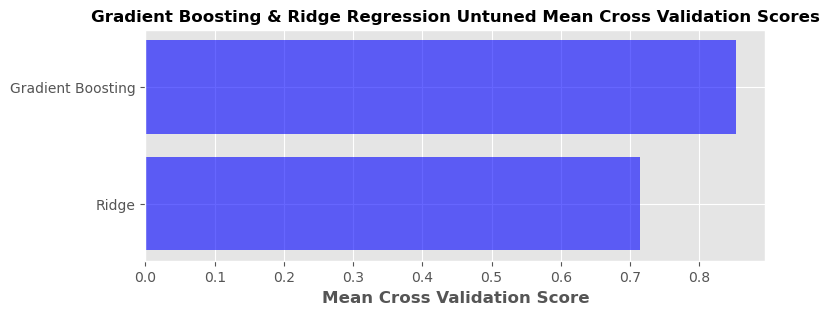

In [38]:
models = ['Ridge', 'Gradient Boosting']
scores = [Ridge_Untuned_CV_Mean, GB_Untuned_CV_Mean]
plt.figure(figsize=(8,3))
plt.barh(models, scores, color='blue', alpha=0.6)
plt.xlabel("Mean Cross Validation Score", fontweight=fontweight)
plt.title("Gradient Boosting & Ridge Regression Untuned Mean Cross Validation Scores", fontsize=fontsize,
          fontweight=fontweight)
plt.show()

**3E: Gradient Boosting Hyperparameter Tuning**

**Sampling of X_Train/y_train is used to manage the computational expense of cross validations on a large dataset using tree based learning. The final model will be fitted and evaluated with all training data.**

In [39]:
X_train_sample = X_train.sample(100000, random_state=random_state)
y_train_sample = y_train.loc[X_train_sample.index]
GB_Grid = {'Gradient_Boosting__max_depth': [5,8,10],
           'Gradient_Boosting__n_estimators': [50, 75, 100]
          }
GB_Search = GridSearchCV(GB_Pipeline, GB_Grid, cv=cv, scoring='r2', verbose=2)
GB_Search.fit(X_train_sample, y_train_sample)
print(output_divider)
print("Gradient Boosting Optimal Parameters:", GB_Search.best_params_)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
[CV] END Gradient_Boosting__max_depth=5, Gradient_Boosting__n_estimators=50; total time=  22.9s
[CV] END Gradient_Boosting__max_depth=5, Gradient_Boosting__n_estimators=50; total time=  22.5s
[CV] END Gradient_Boosting__max_depth=5, Gradient_Boosting__n_estimators=50; total time=  22.4s
[CV] END Gradient_Boosting__max_depth=5, Gradient_Boosting__n_estimators=75; total time=  32.4s
[CV] END Gradient_Boosting__max_depth=5, Gradient_Boosting__n_estimators=75; total time=  31.9s
[CV] END Gradient_Boosting__max_depth=5, Gradient_Boosting__n_estimators=75; total time=  32.1s
[CV] END Gradient_Boosting__max_depth=5, Gradient_Boosting__n_estimators=100; total time=  43.8s
[CV] END Gradient_Boosting__max_depth=5, Gradient_Boosting__n_estimators=100; total time=  44.6s
[CV] END Gradient_Boosting__max_depth=5, Gradient_Boosting__n_estimators=100; total time=  44.0s
[CV] END Gradient_Boosting__max_depth=8, Gradient_Boosting__n_estimators=

In [40]:
GB_Pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('Gradient_Boosting', GradientBoostingRegressor(random_state=random_state,
                                                    max_depth=5, n_estimators=75))])

In [41]:
GB_Tuned_CV = cross_val_score(GB_Pipeline, X_train, y_train, cv=cv, scoring='r2')
GB_Tuned_CV_Mean = GB_Tuned_CV.mean()
print("Tuned Gradient Boosting Cross Validation Scores:", GB_Tuned_CV)
print(output_divider)
print("Tuned Gradient Boosting Mean Cross Validation Score:", GB_Tuned_CV_Mean)

Tuned Gradient Boosting Cross Validation Scores: [0.85708126 0.86544099 0.85800992]
Tuned Gradient Boosting Mean Cross Validation Score: 0.8601773912636492


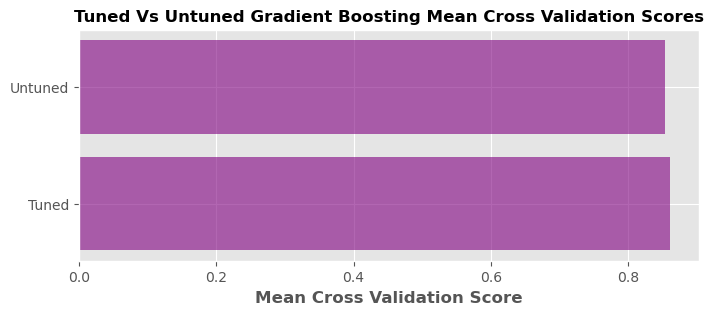

In [42]:
tuning_statuses = ['Tuned', 'Untuned']
scores = [GB_Tuned_CV_Mean, GB_Untuned_CV_Mean]
plt.figure(figsize=(8,3))
plt.barh(tuning_statuses, scores, color='purple', alpha=0.6)
plt.title("Tuned Vs Untuned Gradient Boosting Mean Cross Validation Scores",
          fontweight=fontweight, fontsize=fontsize)
plt.xlabel("Mean Cross Validation Score", fontweight=fontweight)
plt.show()

In [43]:
comments = "Gradient Boosting hyperparameter tuning had minimal impact on improving model performance."
print(comments)

Gradient Boosting hyperparameter tuning had minimal impact on improving model performance.


**3F: Fit Final Gradient Boosting Regression Model & Evaluate Results**

In [44]:
GB_Pipeline.fit(X_train, y_train)
y_pred = GB_Pipeline.predict(X_test)
GB_Test_Score = np.round(GB_Pipeline.score(X_test, y_test), 2)
GB_Training_Score = np.round(GB_Pipeline.score(X_train, y_train), 2)
MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
print("Final Gradient Boosting Model Testing Score:", GB_Test_Score)
print(output_divider)
print("Final Gradient Boosting Model Training Score:", GB_Training_Score)
print(output_divider)
print("Final Gradient Boosting Model Mean Absolute Error:", MAE)
print(output_divider)
print("Final Gradient Boosting Model Mean Squared Error:", MSE)

Final Gradient Boosting Model Testing Score: 0.87
Final Gradient Boosting Model Training Score: 0.87
Final Gradient Boosting Model Mean Absolute Error: 2172.712349718224
Final Gradient Boosting Model Mean Squared Error: 11861210.281607682


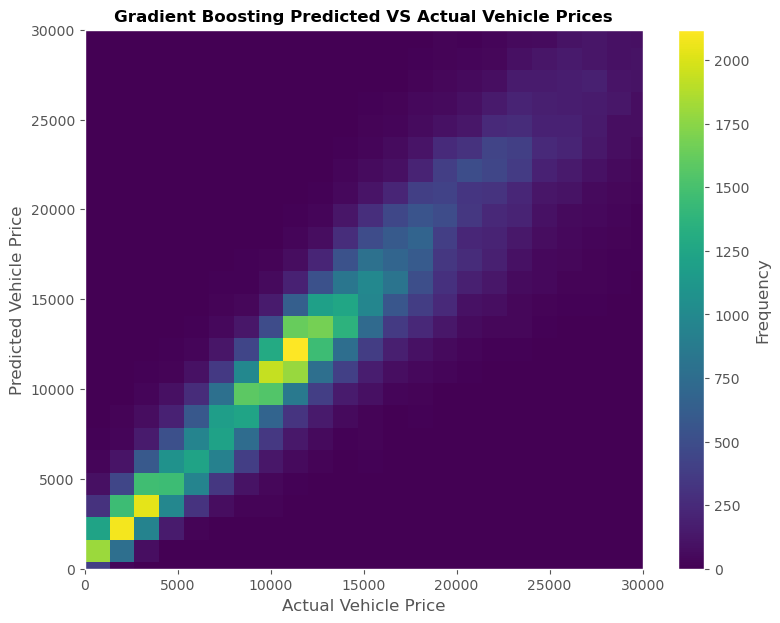

In [50]:
plt.figure(figsize=(9,7))
plt.hist2d(y_test, y_pred, cmap='viridis', bins=125)
plt.xlabel("Actual Vehicle Price")
plt.ylabel("Predicted Vehicle Price")
plt.ylim(0, 30000)
plt.xlim(0, 30000)
plt.title("Gradient Boosting Predicted VS Actual Vehicle Prices",
         fontsize=fontsize, fontweight=fontweight)
plt.colorbar(label='Frequency')
plt.show()

**3G: Feature Evaluation**

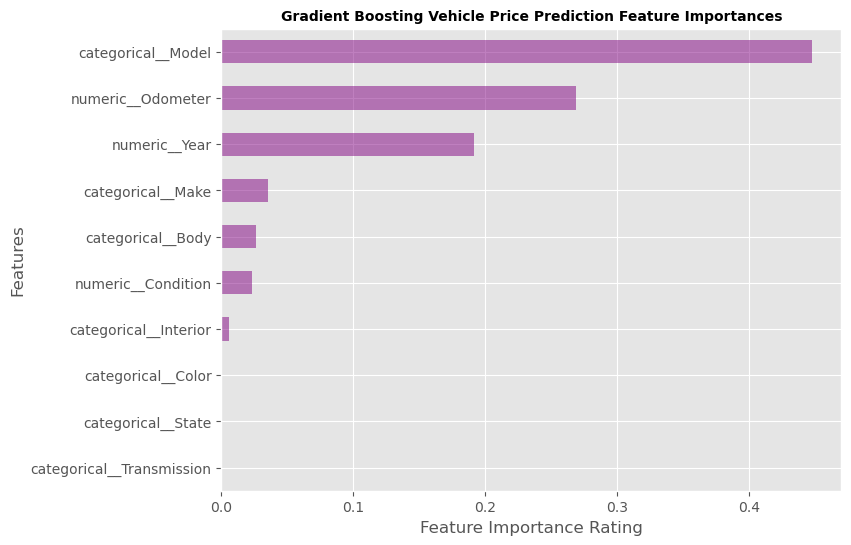

In [54]:
gb_values = GB_Pipeline.named_steps['Gradient_Boosting'].feature_importances_
gb_features = GB_Pipeline.named_steps['preprocessor'].get_feature_names_out()
feature_values = pd.Series(gb_values, index=gb_features).sort_values()
plt.figure(figsize=(8,6))
feature_values.plot(kind='barh', color='purple', alpha=0.5)
plt.title("Gradient Boosting Vehicle Price Prediction Feature Importances", fontweight='bold', fontsize=10)
plt.xlabel("Feature Importance Rating")
plt.ylabel("Features")
plt.show()

**Project Findings:** Gradient Boosting and Ridge Regression models were evaluated on cross validation scoring utilizing allocated
training data. Cross validation R2 scoring proved Gradient Boosting is better suited to capture the variance of this dataset. Tuning the Gradient Boosting n_estimators and max_depth parameters did not result in meaningful increases in scoring. The final Gradient Boosting model achieved a training and testing score of .87 indicating minimal overfitting and 87% of the variance in the data being captured. Feature evaluation proved both numeric and categorical features were critical in developing a price prediction model. Vehicle model, mileage(odometer), year produced, make, and body style proved to be the top five most predictive features of vehicle price.